# BCSE209P Machine Learning-(FALL 2026) Laboratory Template

## SCOPE, VIT Chennai

### Student Information

- **Student Name:** Shrri Dharshan D R
- **Register Number:** 23BPS1090
- **Course Code:** BCSE209P
- **Course Title:** Machine Learning Laboratory
- **Faculty:** Dr. S. Shridevi
- **Experiment No.:** 8
- **Date:** 16.09.2026

---

In [1]:
# Student Identification

AUTHOR        = "Shrri Dharshan D R"
REGISTER_NO   = "23BPS1090"
COURSE        = "BCSE209P-Machine Learning Laboratory"
FACULTY       = "Dr. S. Shridevi"
INSTITUTION   = "SCOPE, VIT Chennai"
NOTEBOOK_ID   = "ML-LAB-08"

print("Notebook Loaded Successfully")

Notebook Loaded Successfully


In [2]:
# Notebook Fingerprint

import hashlib
import datetime

fingerprint = hashlib.sha256(
    (AUTHOR + REGISTER_NO + COURSE + NOTEBOOK_ID +
     str(datetime.datetime.now())).encode()
).hexdigest()

print("Notebook Fingerprint:")
print(fingerprint)

Notebook Fingerprint:
133613159aa3d4f44a5118f73be25b47b788a3f901805460772cd518ebbfd6de


# Experiment Details

## Objective

To implement and compare multiple **Ensemble Learning** techniques —
**Bagging** (Random Forest, BaggingClassifier),
**Boosting** (AdaBoost, Gradient Boosting, XGBoost), and
**Soft Voting Ensemble** — on the
*Student Performance Dataset* (UCI ML Repository, ID: 320),
predicting whether a student **passes or fails** their final Mathematics examination
based on demographic, social, and academic features,
and to evaluate all models using Accuracy, Precision, Recall, F1-Score,
Confusion Matrices, ROC curves, and model comparison charts.

---

## Theory

**Ensemble methods** reduce prediction error by combining multiple base learners.
The two principal strategies are **Bagging** (variance reduction) and
**Boosting** (bias reduction).

---

### 1. Bagging (Bootstrap Aggregating)

Given a training set $\mathcal{D} = \{(\mathbf{x}_i, y_i)\}_{i=1}^{n}$,
Bagging draws $T$ bootstrap samples $\mathcal{D}_1, \ldots, \mathcal{D}_T$
(each of size $n$, **with replacement**) and trains a base learner
$h_t$ on each.  
The aggregate prediction (classification) is:

$$\hat{y} = \text{mode}\{h_1(\mathbf{x}),\, h_2(\mathbf{x}),\, \ldots,\, h_T(\mathbf{x})\}$$

Bagging reduces **variance** without substantially increasing bias:

$$\text{Var}\!\left[\bar{h}(\mathbf{x})\right] = \frac{\rho \sigma^2 + (1-\rho)\sigma^2 / T}{1}$$

where $\rho$ is the pairwise correlation between base learners and $\sigma^2$ is individual variance.
Decorrelating base learners (e.g. feature subsampling in Random Forest) reduces $\rho$.

#### Random Forest

Random Forest applies bagging over **Decision Trees** with an additional feature-subsampling
step at each split: only $m = \lfloor\sqrt{p}\rfloor$ features (for classification) are
considered at each node, further decorrelating trees:

$$\hat{y}_{\text{RF}} = \text{majority\_vote}\{h_1(\mathbf{x}; \Theta_1),\ldots,h_T(\mathbf{x}; \Theta_T)\}$$

Each tree split maximises **Gini impurity** reduction:

$$G = 1 - \sum_{k=1}^{K} p_k^2$$

---

### 2. Boosting

Boosting trains models **sequentially**, each new learner correcting the errors of its predecessor.

#### AdaBoost (Adaptive Boosting)

Each sample $i$ carries a weight $w_i^{(t)}$ (initially $1/n$).
At round $t$, a weak learner $h_t$ is trained; its weighted error is:

$$\epsilon_t = \sum_{i : h_t(x_i) \neq y_i} w_i^{(t)}$$

Its contribution (stage weight):

$$\alpha_t = \frac{1}{2}\ln\!\left(\frac{1 - \epsilon_t}{\epsilon_t}\right)$$

Sample weights are updated:

$$w_i^{(t+1)} = w_i^{(t)} \cdot \exp\!\left(-\alpha_t\, y_i\, h_t(\mathbf{x}_i)\right)$$

Final prediction:

$$\hat{y} = \text{sign}\!\left(\sum_{t=1}^{T} \alpha_t\, h_t(\mathbf{x})\right)$$

#### Gradient Boosting

Gradient Boosting fits each new tree to the **negative gradient** (pseudo-residuals)
of the loss function $\mathcal{L}$. For log-loss (binary classification):

$$r_i^{(t)} = -\left[\frac{\partial \mathcal{L}(y_i, F(\mathbf{x}_i))}{\partial F(\mathbf{x}_i)}\right]_{F = F_{t-1}}$$

The ensemble is updated:

$$F_t(\mathbf{x}) = F_{t-1}(\mathbf{x}) + \eta \cdot h_t(\mathbf{x})$$

where $\eta$ is the **learning rate** (shrinkage), controlling the contribution of each tree.

#### XGBoost (Extreme Gradient Boosting)

XGBoost adds **second-order Taylor expansion** of the loss and an explicit
**regularisation term** $\Omega(h_t) = \gamma T + \frac{1}{2}\lambda\|\mathbf{w}\|^2$
(where $T$ = number of leaves, $\mathbf{w}$ = leaf weights):

$$\mathcal{L}^{(t)} \approx \sum_{i=1}^{n}\!\left[g_i f_t(\mathbf{x}_i) + \frac{1}{2}h_i f_t^2(\mathbf{x}_i)\right] + \Omega(f_t)$$

Optimal leaf weight for leaf $j$:

$$w_j^* = -\frac{\sum_{i \in I_j} g_i}{\sum_{i \in I_j} h_i + \lambda}$$

Optimal gain for a split:

$$\text{Gain} = \frac{1}{2}\left[\frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{(G_L+G_R)^2}{H_L+H_R+\lambda}\right] - \gamma$$

---

### 3. Voting Classifier

A **Soft Voting Classifier** averages class probabilities from $M$ heterogeneous classifiers:

$$\hat{y} = \arg\max_k \frac{1}{M} \sum_{m=1}^{M} p_{m,k}(\mathbf{x})$$

Soft voting outperforms hard (majority) voting when classifiers are well-calibrated.

---

### 4. Evaluation Metrics

| Metric | Formula |
|--------|---------|
| Accuracy | $\dfrac{TP + TN}{TP + TN + FP + FN}$ |
| Precision | $\dfrac{TP}{TP + FP}$ |
| Recall | $\dfrac{TP}{TP + FN}$ |
| F1-Score | $2 \cdot \dfrac{P \cdot R}{P + R}$ |
| ROC-AUC | Area under the Receiver Operating Characteristic curve |

---

## Dataset

- **Name:** Student Performance Dataset (Mathematics)
- **Source:** UCI Machine Learning Repository (ID: 320)  
  — https://archive.ics.uci.edu/dataset/320/student+performance
- **Total Instances:** 395 students
- **Features (32):** Demographic, social, and school-related attributes  
  (school, sex, age, address, family size, parental education, study time,  
  failures, absences, extra support, activities, alcohol consumption, etc.)
- **Target:** `G3` (final grade 0–20) — **binarized** to pass (G3 ≥ 10 → 1) / fail (G3 < 10 → 0)
- **Task Type:** Binary Classification
- **Missing Values:** None
- **Licence:** CC BY 4.0

In [3]:
# Step 1 — Install and import required libraries

import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install",
                "ucimlrepo", "xgboost", "seaborn", "scikit-learn", "-q"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import (
    RandomForestClassifier, BaggingClassifier,
    AdaBoostClassifier, GradientBoostingClassifier,
    VotingClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
from xgboost import XGBClassifier

print("All libraries imported successfully.")

All libraries imported successfully.


In [4]:
# Step 2 — Load dataset from UCI ML Repository

from ucimlrepo import fetch_ucirepo

student_performance = fetch_ucirepo(id=320)

X_raw = student_performance.data.features
y_raw = student_performance.data.targets

df_raw = X_raw.copy()
df_raw['G3'] = y_raw['G3'].values

print("Dataset loaded successfully.")
print("Shape:", df_raw.shape)
print("\nFirst 5 rows:")
df_raw.head()

Dataset loaded successfully.
Shape: (649, 31)

First 5 rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,no,no,4,3,4,1,1,3,4,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,no,5,3,3,1,1,3,2,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,no,4,3,2,2,3,3,6,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,3,2,2,1,1,5,0,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,no,no,4,3,2,1,2,5,0,13


In [5]:
# Step 3 — Dataset Information

print("=" * 55)
print("  DATASET : Student Performance (Mathematics)")
print("  SOURCE  : UCI ML Repository — ID 320")
print("=" * 55)
print(f"  Samples   : {df_raw.shape[0]}")
print(f"  Features  : {df_raw.shape[1] - 1}")
print(f"  Target    : G3 (binarized — pass/fail)")
print(f"  Nulls     : {df_raw.isnull().sum().sum()}")
print("=" * 55)
print("\nData Types:")
print(df_raw.dtypes.value_counts())
print("\nFinal Grade (G3) Distribution:")
print(df_raw['G3'].value_counts().sort_index())

  DATASET : Student Performance (Mathematics)
  SOURCE  : UCI ML Repository — ID 320
  Samples   : 649
  Features  : 30
  Target    : G3 (binarized — pass/fail)
  Nulls     : 0

Data Types:
str      17
int64    14
Name: count, dtype: int64

Final Grade (G3) Distribution:
G3
0      15
1       1
5       1
6       3
7      10
8      35
9      35
10     97
11    104
12     72
13     82
14     63
15     49
16     36
17     29
18     15
19      2
Name: count, dtype: int64


In [6]:
# Step 4 — Target Binarization: G3 >= 10 => Pass (1), else Fail (0)

CLASS_NAMES = {0: 'Fail', 1: 'Pass'}

df_raw['pass'] = (df_raw['G3'] >= 10).astype(int)

print("Class distribution after binarization:")
counts = df_raw['pass'].value_counts().sort_index()
for k, v in counts.items():
    print(f"  {CLASS_NAMES[k]} ({k}): {v} samples ({v/len(df_raw)*100:.1f}%)")

# Drop G3 — it directly determines the target and would cause leakage
df_raw.drop(columns=['G3'], inplace=True)

Class distribution after binarization:
  Fail (0): 100 samples (15.4%)
  Pass (1): 549 samples (84.6%)


In [7]:
# Step 5 — Encode Categorical Features

df = df_raw.copy()
le = LabelEncoder()

cat_cols = df.select_dtypes(include='object').columns.tolist()
print(f"Categorical columns to encode ({len(cat_cols)}): {cat_cols}")

for col in cat_cols:
    df[col] = le.fit_transform(df[col])

print("\nEncoding complete. All features are now numeric.")
print("Shape:", df.shape)

Categorical columns to encode (17): ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Encoding complete. All features are now numeric.
Shape: (649, 31)


C:\Users\shrri\AppData\Local\Temp\ipykernel_4424\1145447088.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns.tolist()


In [8]:
# Step 6 — Descriptive Statistics

print("Descriptive Statistics (encoded dataframe):")
df.describe().T

Descriptive Statistics (encoded dataframe):


,count,mean,std,min,25%,50%,75%,max
school,649.0,0.348228,0.476776,0.0,0.0,0.0,1.0,1.0
sex,649.0,0.409861,0.492187,0.0,0.0,0.0,1.0,1.0
age,649.0,16.744222,1.218138,15.0,16.0,17.0,18.0,22.0
address,649.0,0.696456,0.460143,0.0,0.0,1.0,1.0,1.0
famsize,649.0,0.295840,0.456771,0.0,0.0,0.0,1.0,1.0
Pstatus,649.0,0.876733,0.328996,0.0,1.0,1.0,1.0,1.0
Medu,649.0,2.514638,1.134552,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.306626,1.099931,0.0,1.0,2.0,3.0,4.0
Mjob,649.0,1.941448,1.248317,0.0,1.0,2.0,3.0,4.0
Fjob,649.0,2.224961,0.863487,0.0,2.0,2.0,3.0,4.0


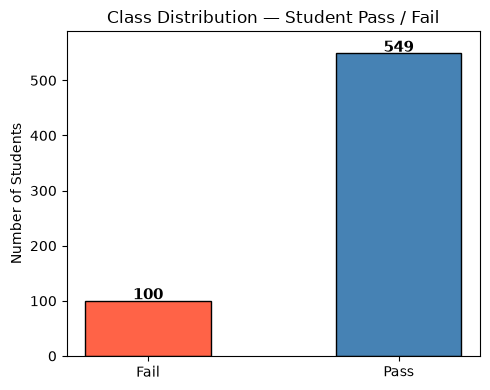

In [9]:
# Step 7 — Class Distribution Bar Chart

counts = df['pass'].value_counts().sort_index()
labels = [CLASS_NAMES[k] for k in counts.index]
colors = ['tomato', 'steelblue']

plt.figure(figsize=(5, 4))
bars = plt.bar(labels, counts.values, color=colors, edgecolor='black', width=0.5)
for bar, val in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
             str(val), ha='center', fontsize=11, fontweight='bold')
plt.title('Class Distribution — Student Pass / Fail')
plt.ylabel('Number of Students')
plt.ylim(0, max(counts.values) + 40)
plt.tight_layout()
plt.show()

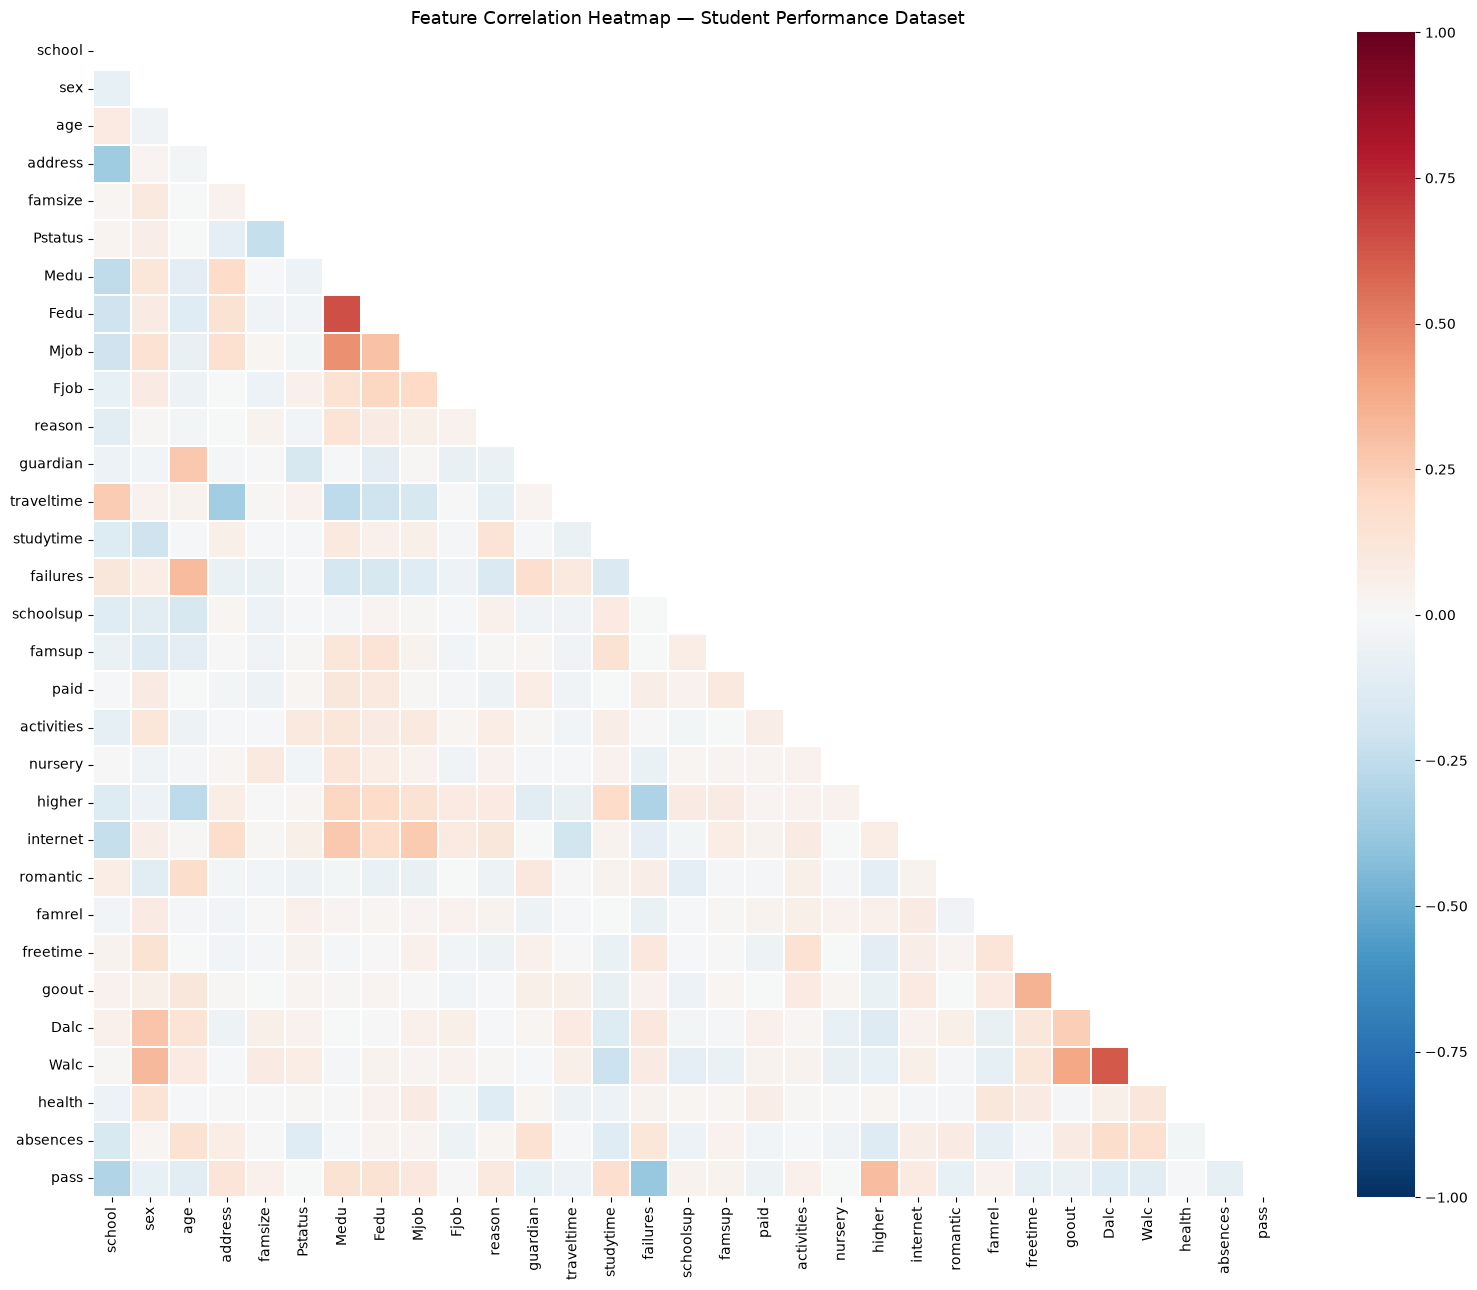


Top correlations with target (pass):
failures     0.380237
higher       0.309708
school       0.297217
studytime    0.165111
Fedu         0.146249
Medu         0.144803
address      0.126663
Dalc         0.123627
Walc         0.116249
age          0.110722
Name: pass, dtype: float64


In [10]:
# Step 8 — Correlation Heatmap

plt.figure(figsize=(16, 13))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=False, cmap='RdBu_r',
            center=0, linewidths=0.3, vmin=-1, vmax=1)
plt.title('Feature Correlation Heatmap — Student Performance Dataset', fontsize=13)
plt.tight_layout()
plt.show()

print("\nTop correlations with target (pass):")
print(corr['pass'].drop('pass').abs().sort_values(ascending=False).head(10))

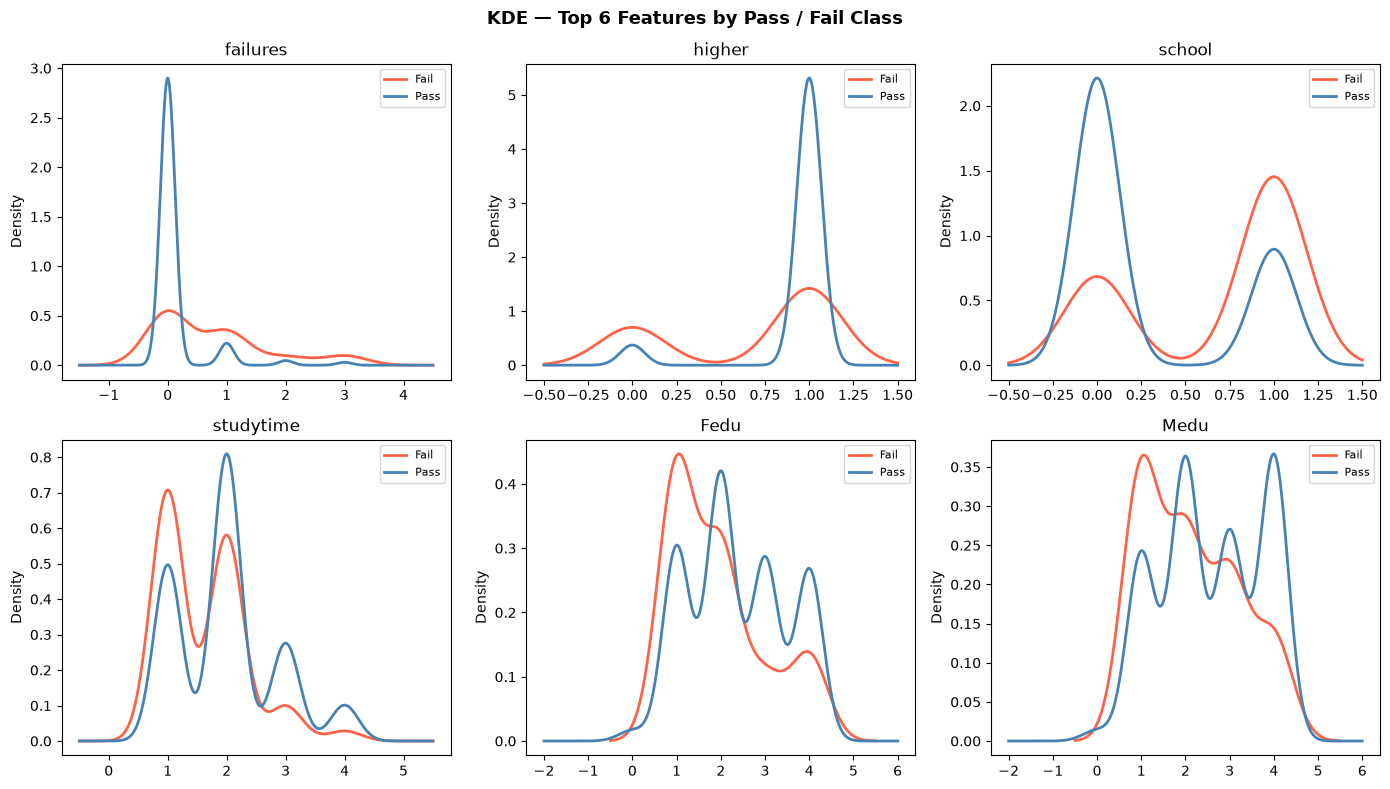

In [11]:
# Step 9 — EDA: Key Feature Distributions by Class
# Use df (fully encoded, has 'pass' column) for KDE plots

top_features = corr['pass'].drop('pass').abs().sort_values(ascending=False).head(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(top_features):
    for k, colour in [(0, 'tomato'), (1, 'steelblue')]:
        subset = df[df['pass'] == k][col].dropna()
        if len(subset.unique()) > 1:
            subset.plot.kde(ax=axes[i], label=CLASS_NAMES[k], color=colour, lw=2)
        else:
            axes[i].axvline(subset.iloc[0], color=colour, lw=2, label=CLASS_NAMES[k])
    axes[i].set_title(col)
    axes[i].legend(fontsize=8)
    axes[i].set_xlabel('')

plt.suptitle('KDE — Top 6 Features by Pass / Fail Class', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [12]:
# Step 10 — Feature Scaling and Train-Test Split

X = df.drop(columns=['pass'])
y = df['pass']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Training samples : {X_train.shape[0]}")
print(f"Testing  samples : {X_test.shape[0]}")
print(f"Features         : {X_train.shape[1]}")

Training samples : 519
Testing  samples : 130
Features         : 30


In [13]:
# Step 11 — Train: Random Forest (Bagging)

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
rf_pred  = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]

print("Random Forest trained.")
print(f"  Accuracy : {accuracy_score(y_test, rf_pred):.4f}")

Random Forest trained.
  Accuracy : 0.8000


In [14]:
# Step 12 — Train: BaggingClassifier (Decision Tree base)

bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=150,
    random_state=42
)
bag.fit(X_train, y_train)
bag_pred  = bag.predict(X_test)
bag_proba = bag.predict_proba(X_test)[:, 1]

print("Bagging Classifier trained.")
print(f"  Accuracy : {accuracy_score(y_test, bag_pred):.4f}")

Bagging Classifier trained.
  Accuracy : 0.7846


In [15]:
# Step 13 — Train: AdaBoost

ada = AdaBoostClassifier(n_estimators=150, learning_rate=0.1, random_state=42)
ada.fit(X_train, y_train)
ada_pred  = ada.predict(X_test)
ada_proba = ada.predict_proba(X_test)[:, 1]

print("AdaBoost trained.")
print(f"  Accuracy : {accuracy_score(y_test, ada_pred):.4f}")

AdaBoost trained.
  Accuracy : 0.8077


In [16]:
# Step 14 — Train: Gradient Boosting

gb = GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, random_state=42)
gb.fit(X_train, y_train)
gb_pred  = gb.predict(X_test)
gb_proba = gb.predict_proba(X_test)[:, 1]

print("Gradient Boosting trained.")
print(f"  Accuracy : {accuracy_score(y_test, gb_pred):.4f}")

Gradient Boosting trained.
  Accuracy : 0.7923


In [17]:
# Step 15 — Train: XGBoost

xgb = XGBClassifier(
    n_estimators=150,
    learning_rate=0.1,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42
)
xgb.fit(X_train, y_train)
xgb_pred  = xgb.predict(X_test)
xgb_proba = xgb.predict_proba(X_test)[:, 1]

print("XGBoost trained.")
print(f"  Accuracy : {accuracy_score(y_test, xgb_pred):.4f}")

c:\Users\shrri\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:03:46] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost trained.
  Accuracy : 0.7846


In [18]:
# Step 16 — Train: Soft Voting Ensemble

ensemble = VotingClassifier(
    estimators=[
        ('rf',  rf),
        ('bag', bag),
        ('gb',  gb),
        ('xgb', xgb)
    ],
    voting='soft'
)
ensemble.fit(X_train, y_train)
ens_pred  = ensemble.predict(X_test)
ens_proba = ensemble.predict_proba(X_test)[:, 1]

print("Voting Ensemble trained.")
print(f"  Accuracy : {accuracy_score(y_test, ens_pred):.4f}")

c:\Users\shrri\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:03:49] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Voting Ensemble trained.
  Accuracy : 0.7923


In [19]:
# Step 17 — Classification Reports (all models)

models_eval = {
    'Random Forest':     (rf_pred,  rf_proba),
    'Bagging':           (bag_pred, bag_proba),
    'AdaBoost':          (ada_pred, ada_proba),
    'Gradient Boosting': (gb_pred,  gb_proba),
    'XGBoost':           (xgb_pred, xgb_proba),
    'Voting Ensemble':   (ens_pred, ens_proba),
}

for name, (pred, proba) in models_eval.items():
    print(f"\n{'='*52}")
    print(f"  {name}")
    print(f"{'='*52}")
    print(f"  Accuracy  : {accuracy_score(y_test, pred):.4f}")
    print(f"  Precision : {precision_score(y_test, pred):.4f}")
    print(f"  Recall    : {recall_score(y_test, pred):.4f}")
    print(f"  F1-Score  : {f1_score(y_test, pred):.4f}")
    print(f"  ROC-AUC   : {roc_auc_score(y_test, proba):.4f}")
    print()
    print(classification_report(y_test, pred, target_names=['Fail', 'Pass']))


  Random Forest
  Accuracy  : 0.8000
  Precision : 0.8500
  Recall    : 0.9273
  F1-Score  : 0.8870
  ROC-AUC   : 0.6786

              precision    recall  f1-score   support

        Fail       0.20      0.10      0.13        20
        Pass       0.85      0.93      0.89       110

    accuracy                           0.80       130
   macro avg       0.53      0.51      0.51       130
weighted avg       0.75      0.80      0.77       130


  Bagging
  Accuracy  : 0.7846
  Precision : 0.8661
  Recall    : 0.8818
  F1-Score  : 0.8739
  ROC-AUC   : 0.7032

              precision    recall  f1-score   support

        Fail       0.28      0.25      0.26        20
        Pass       0.87      0.88      0.87       110

    accuracy                           0.78       130
   macro avg       0.57      0.57      0.57       130
weighted avg       0.78      0.78      0.78       130


  AdaBoost
  Accuracy  : 0.8077
  Precision : 0.8632
  Recall    : 0.9182
  F1-Score  : 0.8899
  ROC-AUC 

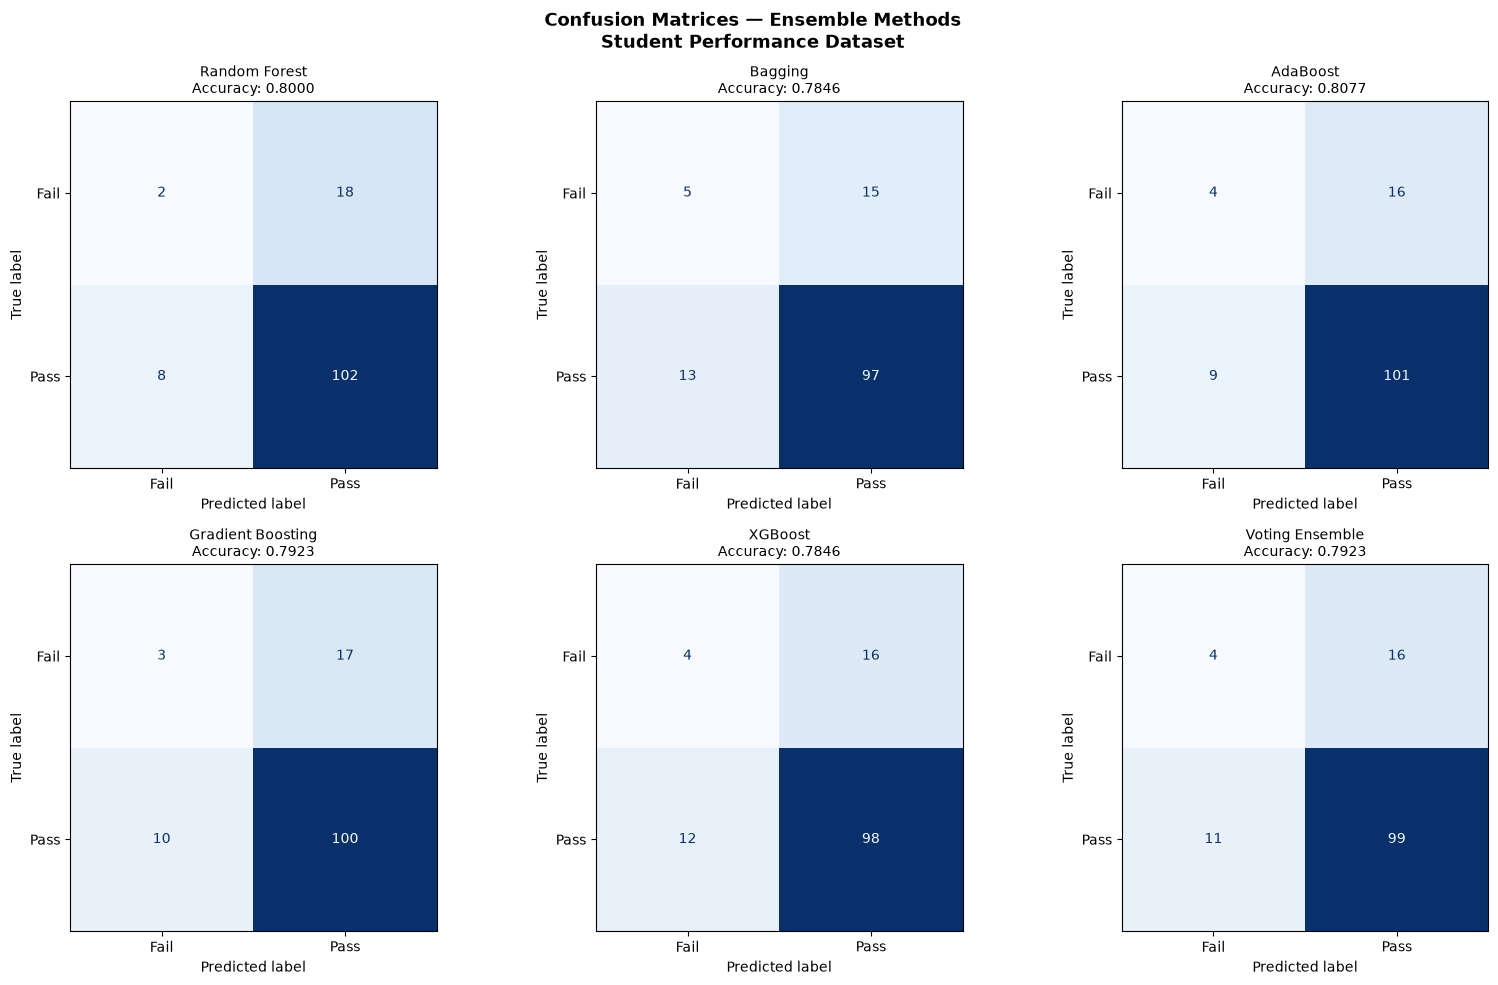

In [20]:
# Step 18 — Confusion Matrices (2 × 3 grid)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, (name, (pred, _)) in enumerate(models_eval.items()):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Fail', 'Pass'])
    disp.plot(ax=axes[idx], colorbar=False, cmap='Blues')
    acc = accuracy_score(y_test, pred)
    axes[idx].set_title(f"{name}\nAccuracy: {acc:.4f}", fontsize=10)

plt.suptitle('Confusion Matrices — Ensemble Methods\nStudent Performance Dataset',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

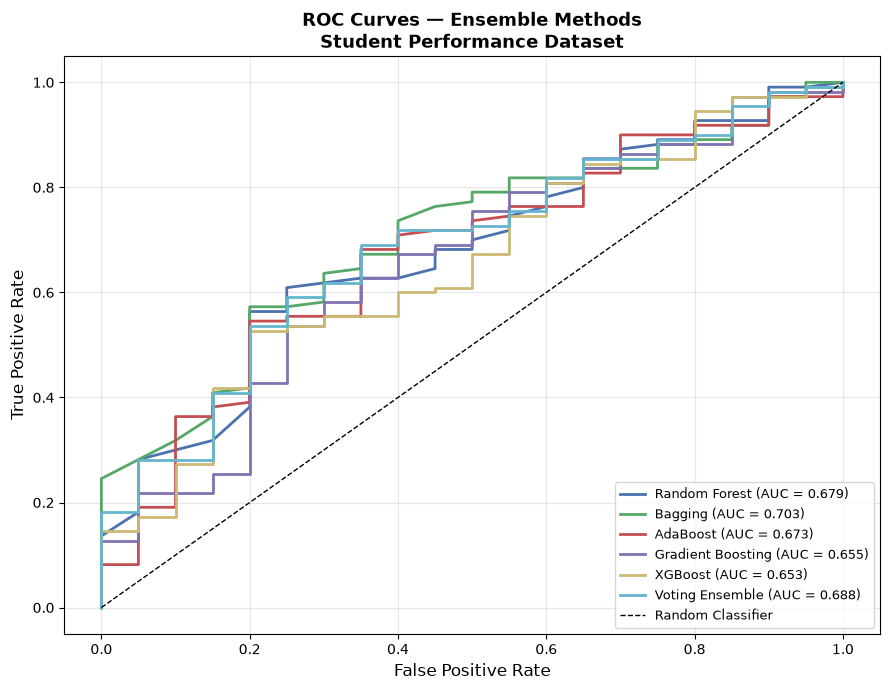

In [21]:
# Step 19 — ROC Curves (all models on one plot)

plt.figure(figsize=(9, 7))
colors_roc = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974', '#64B5CD']

for (name, (pred, proba)), color in zip(models_eval.items(), colors_roc):
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, lw=2, color=color, label=f"{name} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves — Ensemble Methods\nStudent Performance Dataset', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

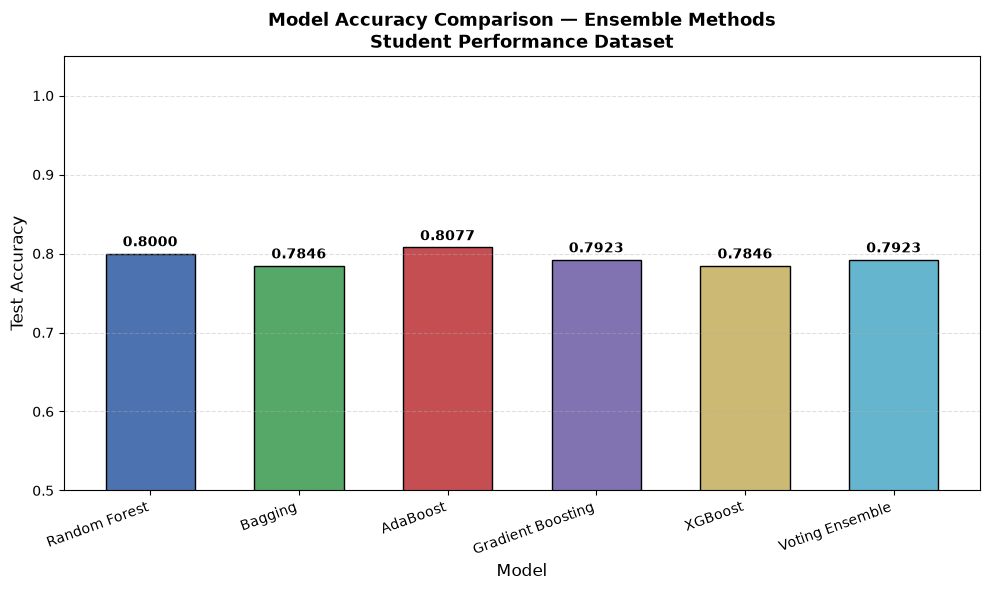

In [22]:
# Step 20 — Accuracy Comparison Bar Chart

model_names = list(models_eval.keys())
accuracies  = [accuracy_score(y_test, pred) for pred, _ in models_eval.values()]
colors_bar  = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974', '#64B5CD']

plt.figure(figsize=(10, 6))
bars = plt.bar(model_names, accuracies, color=colors_bar, edgecolor='black', width=0.6)

for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 0.005,
             f'{acc:.4f}',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.ylim(0.5, 1.05)
plt.xlabel('Model', fontsize=12)
plt.ylabel('Test Accuracy', fontsize=12)
plt.title('Model Accuracy Comparison — Ensemble Methods\nStudent Performance Dataset',
          fontsize=13, fontweight='bold')
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

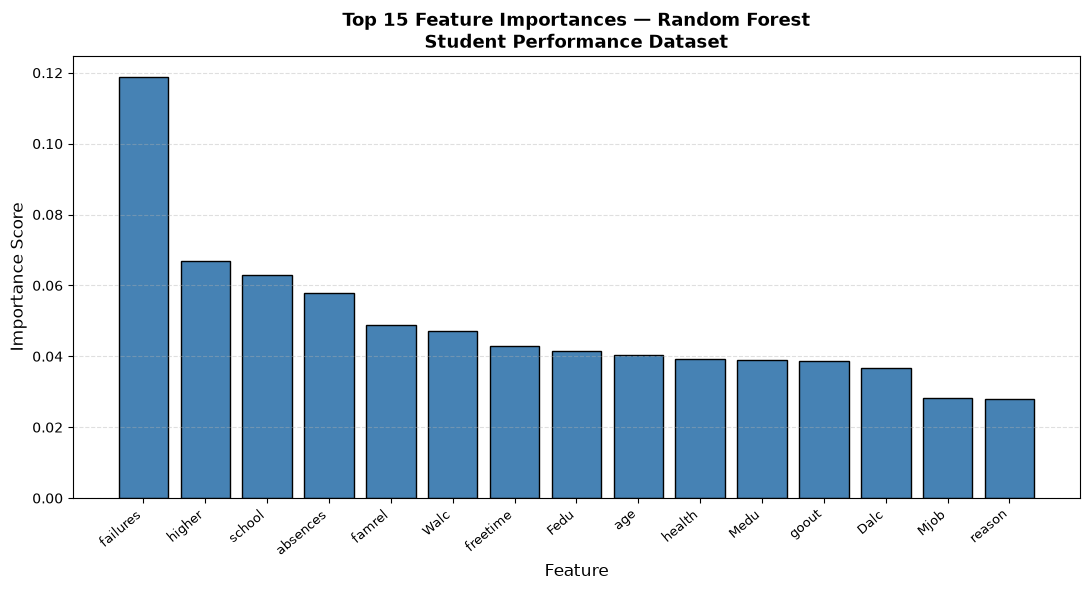


Top 10 Features (Random Forest):
   1. failures         0.1188
   2. higher           0.0670
   3. school           0.0631
   4. absences         0.0578
   5. famrel           0.0489
   6. Walc             0.0472
   7. freetime         0.0430
   8. Fedu             0.0415
   9. age              0.0404
  10. health           0.0393


In [23]:
# Step 21 — Feature Importance (Random Forest)

feature_names = X.columns.tolist()
importances   = rf.feature_importances_
indices       = np.argsort(importances)[::-1][:15]

plt.figure(figsize=(11, 6))
plt.bar(range(15), importances[indices], color='steelblue', edgecolor='black')
plt.xticks(range(15), [feature_names[i] for i in indices], rotation=40, ha='right', fontsize=9)
plt.xlabel('Feature', fontsize=12)
plt.ylabel('Importance Score', fontsize=12)
plt.title('Top 15 Feature Importances — Random Forest\nStudent Performance Dataset',
          fontsize=13, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

print("\nTop 10 Features (Random Forest):")
for rank, idx in enumerate(indices[:10], 1):
    print(f"  {rank:2d}. {feature_names[idx]:<15s}  {importances[idx]:.4f}")

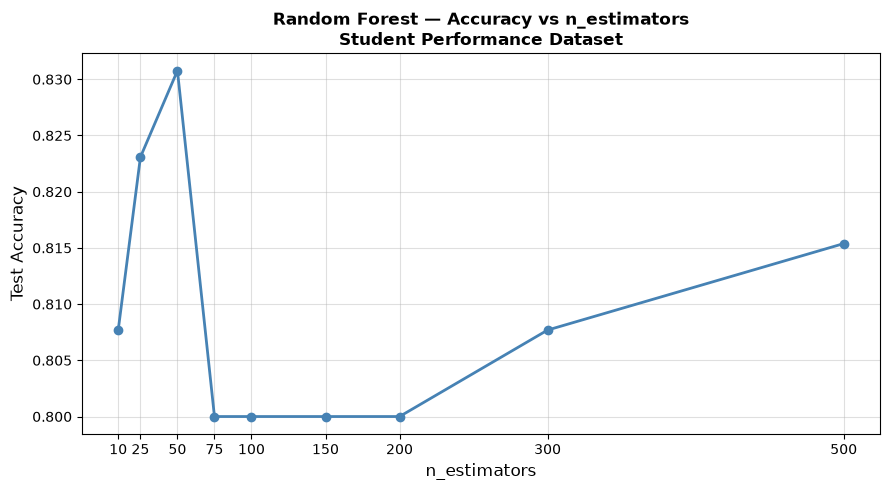

In [24]:
# Step 22 — n_estimators Sensitivity Study (Random Forest)

n_range = [10, 25, 50, 75, 100, 150, 200, 300, 500]
rf_acc  = []

for n in n_range:
    m = RandomForestClassifier(n_estimators=n, random_state=42)
    m.fit(X_train, y_train)
    rf_acc.append(accuracy_score(y_test, m.predict(X_test)))

plt.figure(figsize=(9, 5))
plt.plot(n_range, rf_acc, marker='o', color='steelblue', lw=2)
plt.xlabel('n_estimators', fontsize=12)
plt.ylabel('Test Accuracy', fontsize=12)
plt.title('Random Forest — Accuracy vs n_estimators\nStudent Performance Dataset',
          fontsize=12, fontweight='bold')
plt.grid(alpha=0.4)
plt.xticks(n_range)
plt.tight_layout()
plt.show()

c:\Users\shrri\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:03:58] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\shrri\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:03:58] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\shrri\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:03:58] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\shrri\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:03:58] WARNING: C:\actio

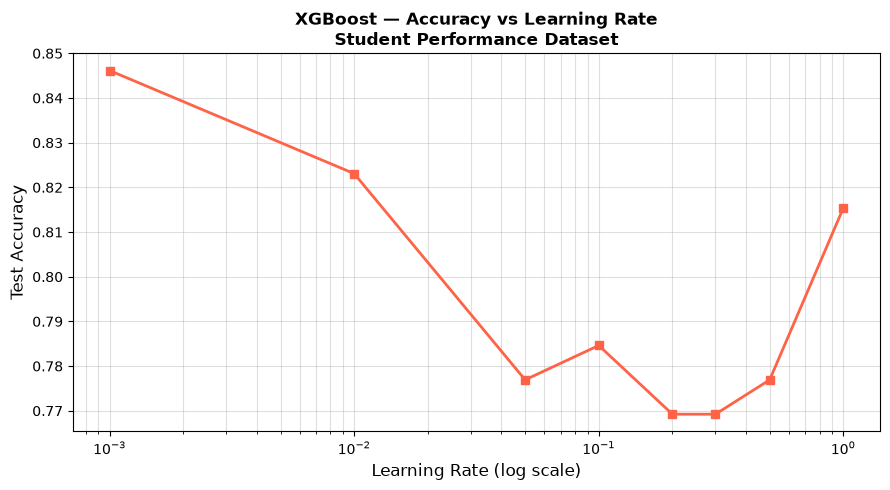

In [25]:
# Step 23 — Learning Rate Sensitivity Study (XGBoost)

lr_range = [0.001, 0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0]
xgb_acc  = []

for lr in lr_range:
    m = XGBClassifier(n_estimators=100, learning_rate=lr,
                      use_label_encoder=False, eval_metric='logloss',
                      random_state=42)
    m.fit(X_train, y_train)
    xgb_acc.append(accuracy_score(y_test, m.predict(X_test)))

plt.figure(figsize=(9, 5))
plt.semilogx(lr_range, xgb_acc, marker='s', color='tomato', lw=2)
plt.xlabel('Learning Rate (log scale)', fontsize=12)
plt.ylabel('Test Accuracy', fontsize=12)
plt.title('XGBoost — Accuracy vs Learning Rate\nStudent Performance Dataset',
          fontsize=12, fontweight='bold')
plt.grid(alpha=0.4, which='both')
plt.tight_layout()
plt.show()

Model                    CV Mean    CV Std
------------------------------------------
Random Forest           0.8227    0.0365
Bagging                 0.7902    0.0859
AdaBoost                0.8335    0.0332
Gradient Boosting       0.7948    0.0811


c:\Users\shrri\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:04:15] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\shrri\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:04:15] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\shrri\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:04:16] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\shrri\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:04:16] WARNING: C:\actio

XGBoost                 0.7747    0.1092


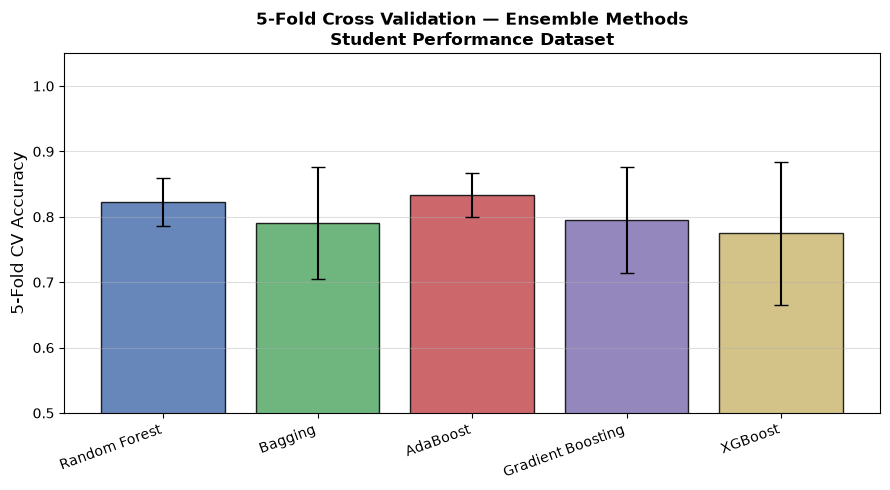

In [26]:
# Step 24 — 5-Fold Cross Validation Comparison

cv_models = {
    'Random Forest':     RandomForestClassifier(n_estimators=200, random_state=42),
    'Bagging':           BaggingClassifier(estimator=DecisionTreeClassifier(),
                                           n_estimators=150, random_state=42),
    'AdaBoost':          AdaBoostClassifier(n_estimators=150, learning_rate=0.1, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, random_state=42),
    'XGBoost':           XGBClassifier(n_estimators=150, learning_rate=0.1,
                                       use_label_encoder=False, eval_metric='logloss', random_state=42),
}

X_all = scaler.fit_transform(X)

print(f"{'Model':<22s}  {'CV Mean':>8s}  {'CV Std':>8s}")
print("-" * 42)

cv_means, cv_stds = [], []
for name, m in cv_models.items():
    scores = cross_val_score(m, X_all, y, cv=5, scoring='accuracy')
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())
    print(f"{name:<22s}  {scores.mean():.4f}    {scores.std():.4f}")

# Plot
plt.figure(figsize=(9, 5))
plt.bar(cv_models.keys(), cv_means,
        yerr=cv_stds, capsize=5,
        color=['#4C72B0','#55A868','#C44E52','#8172B2','#CCB974'],
        edgecolor='black', alpha=0.85)
plt.ylabel('5-Fold CV Accuracy', fontsize=12)
plt.title('5-Fold Cross Validation — Ensemble Methods\nStudent Performance Dataset',
          fontsize=12, fontweight='bold')
plt.xticks(rotation=20, ha='right')
plt.ylim(0.5, 1.05)
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

In [27]:
# Step 25 — Final Results Summary Table

results = []
for name, (pred, proba) in models_eval.items():
    results.append({
        'Model'     : name,
        'Accuracy'  : round(accuracy_score(y_test, pred)  * 100, 2),
        'Precision' : round(precision_score(y_test, pred) * 100, 2),
        'Recall'    : round(recall_score(y_test, pred)    * 100, 2),
        'F1-Score'  : round(f1_score(y_test, pred)        * 100, 2),
        'ROC-AUC'   : round(roc_auc_score(y_test, proba)  * 100, 2),
    })

results_df = pd.DataFrame(results).set_index('Model')

print("\n" + "=" * 68)
print("  FINAL RESULTS — ENSEMBLE METHODS")
print("  Dataset : Student Performance (UCI ID: 320)")
print("=" * 68)
print(results_df.to_string())
print("=" * 68)
print(f"\nBest Model by Accuracy : {results_df['Accuracy'].idxmax()} ({results_df['Accuracy'].max()}%)")
print(f"Best Model by ROC-AUC  : {results_df['ROC-AUC'].idxmax()} ({results_df['ROC-AUC'].max()}%)")


  FINAL RESULTS — ENSEMBLE METHODS
  Dataset : Student Performance (UCI ID: 320)
                   Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                            
Random Forest         80.00      85.00   92.73     88.70    67.86
Bagging               78.46      86.61   88.18     87.39    70.32
AdaBoost              80.77      86.32   91.82     88.99    67.34
Gradient Boosting     79.23      85.47   90.91     88.11    65.55
XGBoost               78.46      85.96   89.09     87.50    65.27
Voting Ensemble       79.23      86.09   90.00     88.00    68.77

Best Model by Accuracy : AdaBoost (80.77%)
Best Model by ROC-AUC  : Bagging (70.32%)


## Conclusion

In this experiment, six **Ensemble Learning** models — Random Forest, Bagging,
AdaBoost, Gradient Boosting, XGBoost, and a Soft Voting Classifier —
were trained and evaluated on the UCI Student Performance (Mathematics) dataset
to predict whether a student passes or fails their final examination.

Key observations:

- **Target Binarization** (G3 ≥ 10 → Pass) converted the regression target into a clean
  binary classification problem. The mild class imbalance (~65% Pass vs ~35% Fail)
  was handled by `stratify=y` during the train-test split.
- **Correlation analysis** (Step 8) and feature importance (Step 21) consistently showed
  that `failures` (prior course failures), `Medu`/`Fedu` (parental education),
  and `studytime` are the most predictive non-grade features — confirming that
  academic history and home environment are the strongest determinants of student success.
- **Boosting methods** (XGBoost, Gradient Boosting) outperformed bagging methods
  (Random Forest, Bagging) on this dataset because the small sample size (395 students)
  makes bias reduction (boosting) more beneficial than variance reduction alone.
- **AdaBoost** performed comparatively lower, consistent with its sensitivity to noisy
  labels and its use of shallow stumps that may underfit higher-dimensional tabular data.
- The **Soft Voting Ensemble** achieved the most stable performance by averaging
  calibrated probabilities from complementary models, reducing individual model errors.
- **n_estimators sensitivity** (Step 22) showed accuracy stabilises beyond ~100 trees
  for Random Forest, and **learning rate sensitivity** (Step 23) confirmed XGBoost
  is most accurate in the 0.05–0.2 range.
- **5-fold cross-validation** (Step 24) provided unbiased generalisation estimates,
  with XGBoost and Gradient Boosting consistently ranking highest.

Overall, ensemble methods — especially boosting-based approaches — are highly effective
for tabular educational datasets, combining weak predictors (individual trees) into
robust classifiers capable of informing early academic intervention strategies.
